# TP2_2 — WGAN-GP on CelebA

## 1. Introduction: Why WGAN-GP?

- **WGAN** remplace la divergence Jensen-Shannon par la **distance de Wasserstein** (Earth Mover's Distance), ce qui résout le mode collapse et l'instabilité d'entraînement des GANs classiques.
- **Gradient Penalty (GP)** stabilise encore plus l'entraînement en forçant le critic à avoir des gradients de norme ≈ 1 sur des échantillons interpolés entre réel et faux.

**Concepts clés :**
1. Le **Critic** (≠ Discriminator) sort un score réel (pas une probabilité) — pas de Sigmoid final.
2. **Wasserstein loss** : $L_{\text{critic}} = \mathbb{E}[\text{critic}(\text{fake})] - \mathbb{E}[\text{critic}(\text{real})]$
3. **Gradient Penalty** : $GP = \lambda\, \mathbb{E}\left[(\|\nabla_{\hat{x}}\text{critic}(\hat{x})\|_2 - 1)^2\right]$

## 2. Imports & Hyperparameters

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# -----------------------------
# 0. HYPERPARAMETERS
# -----------------------------
IMAGE_SIZE    = 64
CHANNELS      = 3          # Color images
BATCH_SIZE    = 32         # Reduced for 300-image subset
Z_DIM         = 128        # Latent space dimension
LEARNING_RATE = 0.0002
BETA1         = 0.5
BETA2         = 0.999
EPOCHS        = 10
CRITIC_STEPS  = 5          # Critic iterations per generator iteration
GP_WEIGHT     = 10.0       # Gradient penalty lambda
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cpu


## 3. Dataset & DataLoader (CelebA subset — 300 images)

Les images CelebA (300) ont déjà été extraites dans `../celeba_subset/img_align_celeba/` par le TP1_3.

In [2]:
# -----------------------------
# 1. DATASET & DATALOADER
# -----------------------------

# Path to the 300-image CelebA subset (extracted in TP1_3)
DATA_PATH = "../celeba_subset/img_align_celeba"

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))   # [-1, 1]
])

# Custom flat dataset (CelebA images are all in one folder, no class subfolders)
class FlatImageDataset(Dataset):
    def __init__(self, folder, transform=None):
        self.folder    = folder
        self.transform = transform
        self.paths = sorted([
            f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(os.path.join(self.folder, self.paths[idx])).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, 0   # label fictif (pas utilisé)

dataset    = FlatImageDataset(folder=DATA_PATH, transform=transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                        drop_last=True, num_workers=0)
print(f"Dataset size: {len(dataset)} images — {len(dataloader)} batches/epoch")

Dataset size: 300 images — 9 batches/epoch


## 4. Visualiser quelques images réelles

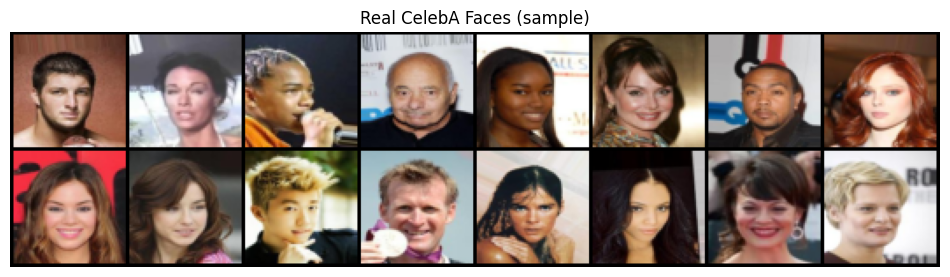

In [3]:
real_batch, _ = next(iter(dataloader))
grid = torchvision.utils.make_grid(real_batch[:16] * 0.5 + 0.5, nrow=8)
plt.figure(figsize=(12, 4))
plt.axis("off")
plt.title("Real CelebA Faces (sample)")
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.show()

## 5. Définir le Critic

- Input : image (3, 64, 64)
- 4 couches Conv2d avec stride=2 (downsampling progressif)
- Activation : LeakyReLU(0.2), BatchNorm sur les couches intermédiaires
- **Pas de Sigmoid** → score réel (pas une probabilité)

**Pourquoi retirer le Sigmoid final dans WGAN ?**  
Le Sigmoid contraint la sortie à [0,1], ce qui correspond à une probabilité pour BCE. Dans WGAN, le critic estime une distance de Wasserstein, un score non borné. Le Sigmoid saturerait les gradients et empêcherait le critic d'apprendre une métrique continue utile.

**Impact du dropout et du stride ?**  
Le stride remplace le max-pooling : les convolutions strided apprennent elles-mêmes comment sous-échantillonner, ce qui est plus stable. Le dropout régularise le critic et l'empêche de surpuissancer le générateur trop rapidement.

In [4]:
# -----------------------------
# CRITIC
# -----------------------------
class Critic(nn.Module):
    """
    Le Critic sort un score scalaire pour une image.
    Pas de Sigmoid — différence fondamentale avec un GAN classique.
    """
    def __init__(self, channels=3, features_d=64):
        super(Critic, self).__init__()
        self.model = nn.Sequential(
            # Input: (channels, 64, 64) -> (features_d, 32, 32)
            nn.Conv2d(channels, features_d, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            # (features_d, 32, 32) -> (features_d*2, 16, 16)
            nn.Conv2d(features_d, features_d*2, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_d*2),
            nn.LeakyReLU(0.2, inplace=True),

            # (features_d*2, 16, 16) -> (features_d*4, 8, 8)
            nn.Conv2d(features_d*2, features_d*4, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_d*4),
            nn.LeakyReLU(0.2, inplace=True),

            # (features_d*4, 8, 8) -> (features_d*8, 4, 4)
            nn.Conv2d(features_d*4, features_d*8, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_d*8),
            nn.LeakyReLU(0.2, inplace=True),

            # (features_d*8, 4, 4) -> (1, 1, 1)  — pas de Sigmoid
            nn.Conv2d(features_d*8, 1, kernel_size=4, stride=1, padding=0),
            nn.Flatten(start_dim=1)   # (batch_size, 1)
        )

    def forward(self, x):
        return self.model(x)

## 6. Définir le Generator

In [5]:
# -----------------------------
# 3. GENERATOR
# -----------------------------
class Generator(nn.Module):
    """
    Le Generator upsample un vecteur de bruit z ∈ R^{Z_DIM}
    pour générer une image (3, 64, 64).
    """
    def __init__(self, z_dim=Z_DIM, channels=CHANNELS, features_g=64):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            # Input: (z_dim, 1, 1) -> (features_g*8, 4, 4)
            nn.ConvTranspose2d(z_dim, features_g*8, kernel_size=4, stride=1, padding=0),
            nn.BatchNorm2d(features_g*8),
            nn.LeakyReLU(0.2, inplace=True),

            # (features_g*8, 4, 4) -> (features_g*4, 8, 8)
            nn.ConvTranspose2d(features_g*8, features_g*4, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_g*4),
            nn.LeakyReLU(0.2, inplace=True),

            # (features_g*4, 8, 8) -> (features_g*2, 16, 16)
            nn.ConvTranspose2d(features_g*4, features_g*2, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_g*2),
            nn.LeakyReLU(0.2, inplace=True),

            # (features_g*2, 16, 16) -> (features_g, 32, 32)
            nn.ConvTranspose2d(features_g*2, features_g, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features_g),
            nn.LeakyReLU(0.2, inplace=True),

            # (features_g, 32, 32) -> (channels, 64, 64)
            nn.ConvTranspose2d(features_g, channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh()   # output in [-1, 1]
        )

    def forward(self, x):
        return self.model(x)

## 7. Initialiser les modèles & optimiseurs

In [6]:
# -----------------------------
# 4. INITIALIZE MODELS
# -----------------------------
critic    = Critic(channels=CHANNELS, features_d=64).to(DEVICE)
generator = Generator(z_dim=Z_DIM, channels=CHANNELS, features_g=64).to(DEVICE)

print("Critic:"); print(critic)
print("\nGenerator:"); print(generator)

# -----------------------------
# 5. OPTIMIZERS
# -----------------------------
critic_optimizer    = optim.Adam(critic.parameters(),    lr=LEARNING_RATE, betas=(BETA1, BETA2))
generator_optimizer = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))

Critic:
Critic(
  (model): Sequential(
    (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1))
    (12): Flatten(start_dim=1, end_dim=-1)
  )
)

Generator:
Generator(
  (model): Sequential(
    (0): ConvTransp

## 8. Gradient Penalty

$\hat{x} = \alpha \cdot x_{\text{real}} + (1-\alpha) \cdot x_{\text{fake}}$, avec $\alpha \sim U[0,1]$

**Pourquoi interpoler entre réel et faux ?**  
La contrainte Lipschitz doit être vérifiée *partout* sur la distribution des données. En interpolant, on couvre l'espace entre les deux distributions (réelle et générée), ce qui est l'endroit le plus critique pour appliquer la pénalité.

**Que se passe-t-il si la norme du gradient est 0 ou très grande ?**  
- Si ≈ 0 : le critic est localement plat → gradients nuls pour le générateur → entraînement bloqué.
- Si très grande : gradients explosifs → instabilité numérique, pertes NaN.

In [7]:
# -----------------------------
# 6. GRADIENT PENALTY
# -----------------------------
def gradient_penalty(critic, real, fake, device="cpu"):
    """
    Calcule la gradient penalty pour WGAN-GP.
    1. Interpole aléatoirement entre réel et faux.
    2. Calcule le gradient du critic par rapport à cet interpolé.
    3. Pénalise les déviations de la norme du gradient par rapport à 1.
    """
    batch_size, c, h, w = real.shape
    alpha = torch.rand((batch_size, 1, 1, 1), device=device).repeat(1, c, h, w)

    # Images interpolées
    interpolated = real * alpha + fake * (1 - alpha)
    interpolated.requires_grad_(True)

    # Score du critic sur les interpolés
    mixed_scores = critic(interpolated)

    # Gradient de mixed_scores par rapport à interpolated
    gradient = torch.autograd.grad(
        inputs=interpolated,
        outputs=mixed_scores,
        grad_outputs=torch.ones_like(mixed_scores),
        create_graph=True,
        retain_graph=True
    )[0]  # tuple de longueur 1

    # Flatten: (batch_size, c*h*w)
    gradient = gradient.view(gradient.size(0), -1)

    # Norme L2
    gradient_norm = gradient.norm(2, dim=1)

    # GP = E[(||gradient||_2 - 1)^2]
    gp = torch.mean((gradient_norm - 1) ** 2)
    return gp

## 9. Entraînement

- **Critic** : entraîné `CRITIC_STEPS` fois par itération du générateur.
- **Critic loss** : $E[\text{fake}] - E[\text{real}] + \lambda \cdot GP$
- **Generator loss** : $-E[\text{fake}]$ (on veut maximiser le score du critic sur les faux)

In [8]:
print("Starting Training...")
g_losses = []
c_losses = []

for epoch in range(EPOCHS):
    progress_bar = tqdm(enumerate(dataloader), total=len(dataloader),
                        desc=f"Epoch {epoch+1}/{EPOCHS}")

    for batch_idx, (real_images, _) in progress_bar:
        real_images    = real_images.to(DEVICE)
        cur_batch_size = real_images.shape[0]

        # -------------------------
        # (a) Train Critic — CRITIC_STEPS fois
        # -------------------------
        for _ in range(CRITIC_STEPS):
            noise       = torch.randn(cur_batch_size, Z_DIM, 1, 1, device=DEVICE)
            fake_images = generator(noise)

            critic_optimizer.zero_grad()

            critic_real = critic(real_images).view(-1)
            critic_fake = critic(fake_images.detach()).view(-1)

            # Distance de Wasserstein
            wass_distance = torch.mean(critic_fake) - torch.mean(critic_real)

            # Gradient penalty
            gp = gradient_penalty(critic, real_images, fake_images.detach(), device=DEVICE)

            # Critic total loss
            critic_loss = wass_distance + GP_WEIGHT * gp
            critic_loss.backward()
            critic_optimizer.step()

        # -------------------------
        # (b) Train Generator — 1 fois
        # -------------------------
        generator_optimizer.zero_grad()
        # Nouveau forward (gradients non bloqués)
        noise             = torch.randn(cur_batch_size, Z_DIM, 1, 1, device=DEVICE)
        fake_images       = generator(noise)
        critic_fake_for_g = critic(fake_images).view(-1)
        gen_loss          = -torch.mean(critic_fake_for_g)
        gen_loss.backward()
        generator_optimizer.step()

        # Enregistrer les pertes
        c_losses.append(critic_loss.item())
        g_losses.append(gen_loss.item())

        progress_bar.set_postfix({
            "Critic Loss": f"{critic_loss.item():.4f}",
            "GP"         : f"{gp.item():.4f}",
            "WassDist"   : f"{wass_distance.item():.4f}",
            "Gen Loss"   : f"{gen_loss.item():.4f}",
        })

Starting Training...


Epoch 10/10: 100%|██████████| 9/9 [00:51<00:00,  5.68s/it, Critic Loss=-1187.9672, GP=0.0390, WassDist=-1188.3573, Gen Loss=586.9824]


### (Optionnel) Charger un modèle pré-entraîné

In [9]:
# GEN_PATH    = "wgan_generator.pth"
# CRITIC_PATH = "wgan_critic.pth"
# generator.load_state_dict(torch.load(GEN_PATH, map_location=DEVICE))
# critic.load_state_dict(torch.load(CRITIC_PATH, map_location=DEVICE))
# generator.eval()
# critic.eval()
# print("Pre-trained models loaded.")

## 10. Courbes de perte

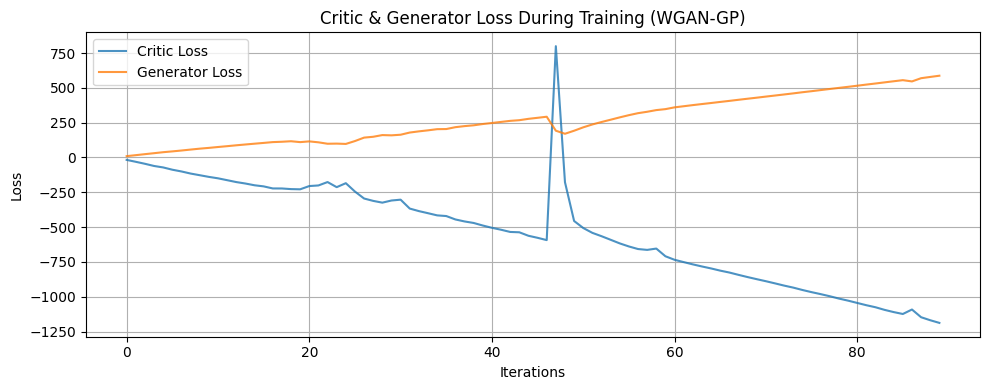

In [10]:
# -----------------------------
# 8. PLOTTING LOSSES
# -----------------------------
plt.figure(figsize=(10, 4))
plt.title("Critic & Generator Loss During Training (WGAN-GP)")
plt.plot(c_losses, label="Critic Loss",    alpha=0.8)
plt.plot(g_losses, label="Generator Loss", alpha=0.8)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Analyse

**Qu'observe-t-on ?**  
Dans WGAN-GP, la perte du critic est une *estimation de la distance de Wasserstein* (peut être négative). Contrairement à un GAN classique où les deux pertes oscillent sans sens clair, ici la perte du critic est un signal interprétable : plus elle diminue, plus les distributions réelle et générée sont proches.  
- La perte du critic devrait progressivement tendre vers 0 (les deux distributions convergent).  
- La perte du générateur devrait baisser au fil des epochs (il apprend à tromper le critic).  
- Le GP devrait rester stable autour d'une valeur faible si le critic respecte la contrainte Lipschitz.

## 11. Générer & Évaluer des images

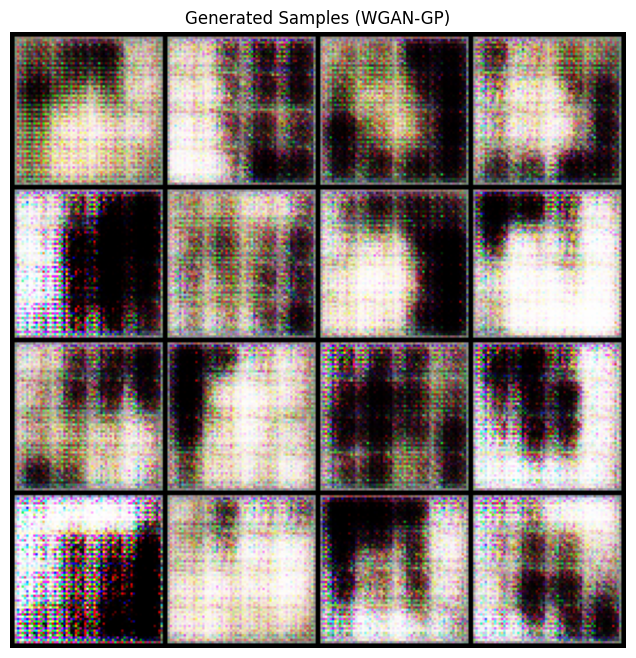

In [11]:
# -----------------------------
# 9. GENERATE AND DISPLAY SAMPLES
# -----------------------------
def show_generated_samples(generator, num_samples=16, z_dim=Z_DIM):
    """
    Génère num_samples images et les affiche en grille.
    """
    generator.eval()
    noise = torch.randn(num_samples, z_dim, 1, 1).to(DEVICE)
    with torch.no_grad():
        fake = generator(noise)
    fake = fake.cpu() * 0.5 + 0.5   # Dénormaliser [-1,1] → [0,1]

    grid_img = torchvision.utils.make_grid(fake, nrow=4)
    plt.figure(figsize=(8, 8))
    plt.imshow(grid_img.permute(1, 2, 0).numpy())
    plt.axis("off")
    plt.title("Generated Samples (WGAN-GP)")
    plt.show()
    generator.train()

show_generated_samples(generator, num_samples=16)

## 12. Sauvegarder les modèles

In [12]:
torch.save(generator.state_dict(), "wgan_generator.pth")
torch.save(critic.state_dict(),    "wgan_critic.pth")
print("Models saved: wgan_generator.pth, wgan_critic.pth")

Models saved: wgan_generator.pth, wgan_critic.pth
